Slope: 9.0
Intercept: 31.0
Predicted Marks: 85.0


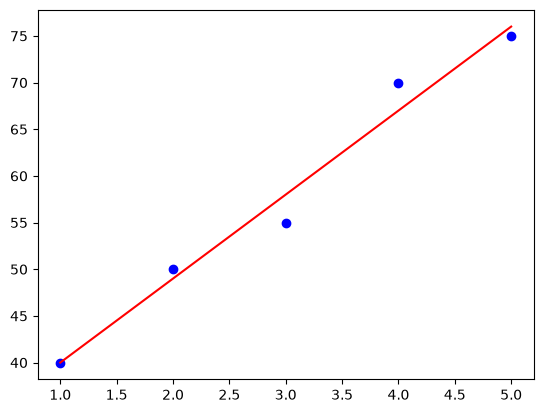

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)

y = np.array([40, 50, 55, 70, 75])

model = LinearRegression()

model.fit(X, y)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

prediction = model. predict([[6]])

print("Predicted Marks:", prediction[0])

plt.scatter(X, y, color="blue", label="Actual Marks")

plt.plot(X, model.predict(X),
color="red", label="Regression Line")

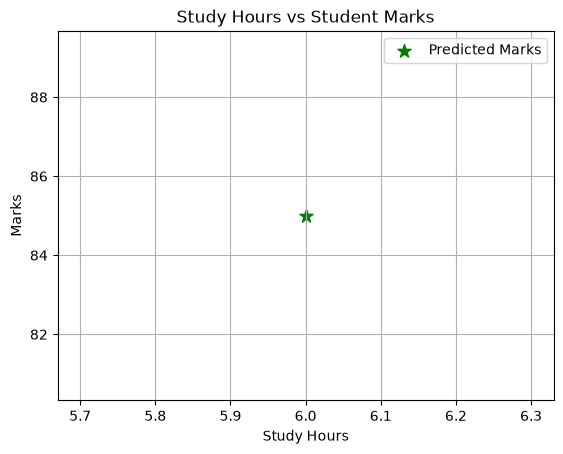

In [8]:
plt.scatter(6, prediction[0],
            color="green", s=100, marker="*",
            label="Predicted Marks")

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Student Marks")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn. linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)

y = np.array([40, 50, 55, 70, 75])

model = LinearRegression()

model.fit(X, y)

y_pred = model.predict(X)

r2 = r2_score(y, y_pred)

mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)

print("R-squared:", r2)
print("R-squared Percentage:", r2 * 100, "%")
print("RMSE:", rmse)

R-squared: 0.9759036144578314
R-squared Percentage: 97.59036144578313 %
RMSE: 2.0


Predicted Marks for 6 Hours: 85.0


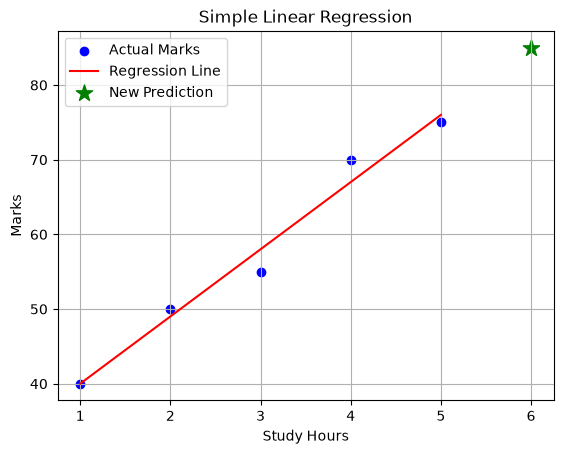

In [10]:
prediction = model. predict([[6]])
print("Predicted Marks for 6 Hours:", prediction[0])

plt.scatter(X, y, color="blue", label="Actual Marks")
plt.plot(X, y_pred, color="red", label="Regression Line")

plt.scatter(6, prediction[0], color="green",
marker="*", s=150, label="New Prediction")

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

data = {
    'StudyHours': [1, 2, 3, 4, 5],
    'Attendance': [40, 20, 60, 100, 80],
    'Marks': [18, 17, 25, 33, 32]
}

df = pd.DataFrame(data)

print("Student Dataset:")
print(df)

X = df[['StudyHours', 'Attendance']]
y = df['Marks']

model = LinearRegression()

model.fit(X, y)

print("\nIntercept:", model.intercept_)
print("Study Hours Coefficient:", model.coef_[0])
print("Attendance Coefficient:", model.coef_[1])

print("\nRegression Equation:")

print(
    f"Marks = {model.intercept_:.2f} "
    f"+ {model.coef_[0]:.2f} * StudyHours "
    f"+ {model.coef_[1]:.2f} * Attendance"
)

y_pred = model.predict(X)

df['PredictedMarks'] = y_pred

print("\nActual vs Predicted Marks:")
print(df)


Student Dataset:
   StudyHours  Attendance  Marks
0           1          40     18
1           2          20     17
2           3          60     25
3           4         100     33
4           5          80     32

Intercept: 10.000000000000002
Study Hours Coefficient: 2.0000000000000004
Attendance Coefficient: 0.14999999999999994

Regression Equation:
Marks = 10.00 + 2.00 * StudyHours + 0.15 * Attendance

Actual vs Predicted Marks:
   StudyHours  Attendance  Marks  PredictedMarks
0           1          40     18            18.0
1           2          20     17            17.0
2           3          60     25            25.0
3           4         100     33            33.0
4           5          80     32            32.0



New Student Details:
   StudyHours  Attendance
0           6          90
Predicted Marks: 35.5

R-squared: 1.0
R-squared Percentage: 100.0 %

Mean Squared Error: 0.0
RMSE: 0.0


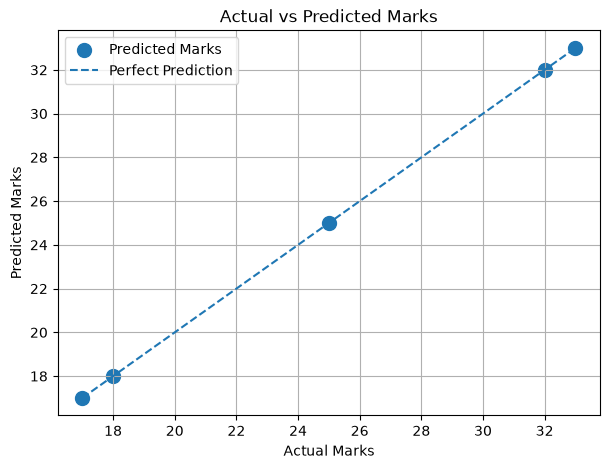

In [12]:
new_student = pd.DataFrame({
    'StudyHours': [6],
    'Attendance': [90]
})

new_prediction = model.predict(new_student)

print("\nNew Student Details:")
print(new_student)

print("Predicted Marks:", new_prediction[0])

r2 = r2_score(y, y_pred)

print("\nR-squared:", r2)
print("R-squared Percentage:", r2 * 100, "%")

mse = mean_squared_error(y, y_pred)

rmse = np.sqrt(mse)

print("\nMean Squared Error:", mse)
print("RMSE:", rmse)

plt.figure(figsize=(7, 5))

plt.scatter(y, y_pred, s=100, label="Predicted Marks")

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    linestyle='--',
    label="Perfect Prediction"
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")

plt.legend()
plt.grid()
plt.show()


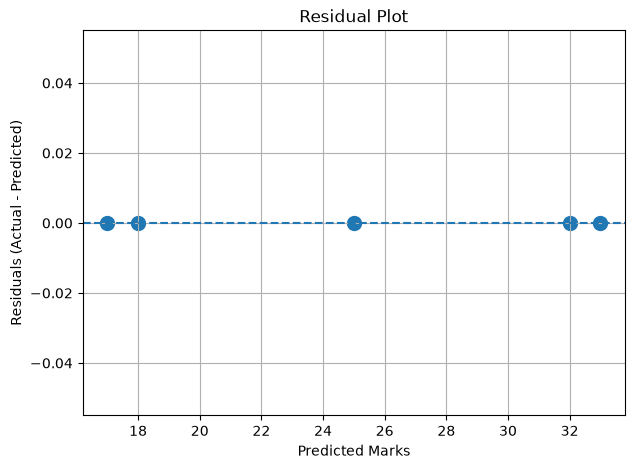

In [13]:
residuals = y - y_pred

plt.figure(figsize=(7, 5))

plt.scatter(y_pred, residuals, s=100)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Marks")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")

plt.grid()
plt.show()


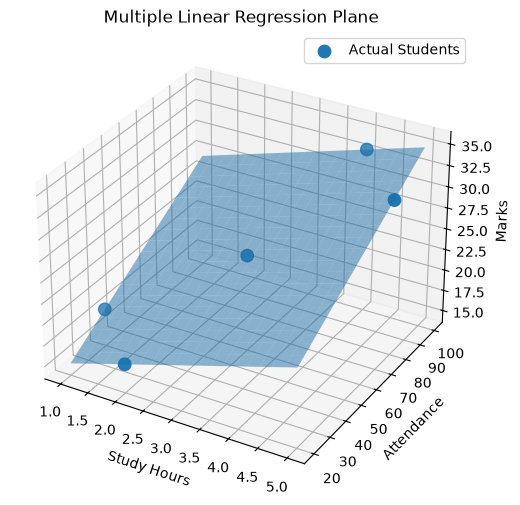

In [14]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection='3d')

study_range = np.linspace(1, 5, 20)
attendance_range = np.linspace(20, 100, 20)

study_grid, attendance_grid = np.meshgrid(
    study_range, attendance_range
)

plane_input = pd.DataFrame({
    'StudyHours': study_grid.ravel(),
    'Attendance': attendance_grid.ravel()
})

marks_grid = model.predict(plane_input).reshape(study_grid.shape)

ax.plot_surface(
    study_grid,
    attendance_grid,
    marks_grid,
    alpha=0.5
)

ax.scatter(
    df['StudyHours'],
    df['Attendance'],
    df['Marks'],
    s=80,
    label="Actual Students"
)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendance")
ax.set_zlabel("Marks")
ax.set_title("Multiple Linear Regression Plane")

ax.legend()

plt.show()
